# Lab 02 · tiny GPT를 처음부터 끝까지: 데이터 → 토크나이저 → 모델 → 학습 → 가중치 저장 → 모델 카드

**대응하는 공부 단계**: [02_study-method.md](../02_study-method.md)의 4단계(작은 규모로 직접 학습하기)

규모는 작아도(약 80만 파라미터, CPU 몇 분) 과정은 대형 모델과 같습니다. 각 절은 [03_training-pipeline.md](../03_training-pipeline.md)의 같은 이름의 단계에 대응합니다.

| 절 | 단계 | 대형 모델에서는 |
|---|---|---|
| 1 | 데이터 | 수조 토큰의 웹·코드·논문 |
| 2 | 토크나이저 | 수만~수십만 어휘의 BPE |
| 3 | 모델 구조 | 수십 층, 폭 수천 |
| 4 | 사전학습 | GPU 수백~천 개, 수 주 |
| 5 | 평가·생성 | 벤치마크 수십 개 |
| 6 | 체크포인트 저장·재로딩 | safetensors + config |
| 7 | 모델 카드 | Hugging Face의 README |

구조와 설정은 [nanoGPT](https://github.com/karpathy/nanoGPT) README의 CPU용 예(4층, 4헤드, 폭 128, 문맥 64)를 따랐고, 코드는 교육용으로 새로 썼습니다.

**소요 시간**: 60~90분(실행은 CPU 약 3분) · **패키지**: torch, safetensors, matplotlib

In [1]:
import math, json, os, tempfile, time, urllib.request, numpy as np, matplotlib.pyplot as plt, torch, torch.nn as nn, torch.nn.functional as F
torch.manual_seed(0)
plt.rcParams.update({"figure.figsize": (7, 3.2), "figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})

## 1. 데이터

셰익스피어 희곡 모음(약 110만 글자)입니다. 내려받지 못하면 짧은 대체 텍스트를 씁니다. 앞 90%를 학습, 뒤 10%를 검증에 씁니다.

✍️ **예측**: 검증 데이터를 따로 떼어 두지 않으면 무엇을 알 수 없게 될까요?

In [2]:
URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
try:
    text = urllib.request.urlopen(URL, timeout=30).read().decode("utf-8")
except Exception:
    text = ("To be, or not to be, that is the question:\nWhether 'tis nobler in the mind to suffer\n"
            "The slings and arrows of outrageous fortune,\nOr to take arms against a sea of troubles\n") * 400
print(f"글자 수: {len(text):,}\n--- 앞부분 ---\n{text[:200]}")

글자 수: 1,115,394
--- 앞부분 ---
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you


## 2. 토크나이저 (글자 단위)

가장 단순한 토크나이저: 글자 하나 = 토큰 하나. 어휘가 작아 학습이 빠릅니다. (BPE는 [LLM Lab 01](../../04_NLP_LLM/labs/lab01_tokenizer_attention_from_scratch.ipynb)에서 만들었습니다.)

In [3]:
chars = sorted(set(text)); vocab_size = len(chars)
stoi = {c: i for i, c in enumerate(chars)}; itos = {i: c for c, i in stoi.items()}
encode = lambda s: [stoi[c] for c in s]
decode = lambda ids: "".join(itos[int(i)] for i in ids)
data = torch.tensor(encode(text), dtype=torch.long)
n_train = int(0.9 * len(data)); train_data, val_data = data[:n_train], data[n_train:]
print("어휘 크기:", vocab_size, "| 학습 토큰:", f"{len(train_data):,}", "| 검증 토큰:", f"{len(val_data):,}")
print("encode('To be') =", encode("To be"), "→ decode →", repr(decode(encode("To be"))))
print(f"아무것도 모르는 모델의 손실(균등 분포) = ln({vocab_size}) = {math.log(vocab_size):.3f}")

어휘 크기: 65 | 학습 토큰: 1,003,854 | 검증 토큰: 111,540
encode('To be') = [32, 53, 1, 40, 43] → decode → 'To be'
아무것도 모르는 모델의 손실(균등 분포) = ln(65) = 4.174


## 3. 모델 구조

GPT 한 개의 전체 정의입니다. [LLM Lab 01](../../04_NLP_LLM/labs/lab01_tokenizer_attention_from_scratch.ipynb)의 어텐션, [DL Lab 02](../../03_Deep_Learning/labs/lab02_training_dynamics.ipynb)의 잔차 연결·LayerNorm이 그대로 들어갑니다.

✍️ **예측**: 4층, 폭 128, 어휘 65, 문맥 64이면 파라미터는 몇 개쯤일까요? (블록 하나 ≈ 12·d²)

In [4]:
class Block(nn.Module):
    def __init__(self, d, n_head):
        super().__init__()
        self.n_head = n_head
        self.ln1, self.ln2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.qkv = nn.Linear(d, 3 * d, bias=False); self.proj = nn.Linear(d, d, bias=False)
        self.mlp = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d))
    def forward(self, x):
        B, T, d = x.shape
        q, k, v = self.qkv(self.ln1(x)).view(B, T, 3, self.n_head, d // self.n_head).permute(2, 0, 3, 1, 4)   # 각각 (B, 헤드, T, d_head)
        att = F.scaled_dot_product_attention(q, k, v, is_causal=True)                                        # 미래를 가린 어텐션
        x = x + self.proj(att.transpose(1, 2).reshape(B, T, d))       # 잔차 연결 1 (pre-norm)
        return x + self.mlp(self.ln2(x))                              # 잔차 연결 2

class TinyGPT(nn.Module):
    def __init__(self, vocab_size, block_size=64, n_layer=4, n_head=4, d=128, use_pos=True):
        super().__init__()
        self.config = dict(vocab_size=vocab_size, block_size=block_size, n_layer=n_layer, n_head=n_head, d=d, use_pos=use_pos)
        self.tok_emb = nn.Embedding(vocab_size, d); self.pos_emb = nn.Embedding(block_size, d)
        self.blocks = nn.ModuleList([Block(d, n_head) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(d); self.head = nn.Linear(d, vocab_size, bias=False)
        self.head.weight = self.tok_emb.weight                        # 입력 임베딩과 출력층의 가중치 공유
        self.apply(self._init)                                        # 작은 값으로 초기화 → 처음에는 모든 토큰에 비슷한 확률
    @staticmethod
    def _init(m):
        if isinstance(m, (nn.Linear, nn.Embedding)): nn.init.normal_(m.weight, std=0.02)
        if isinstance(m, nn.Linear) and m.bias is not None: nn.init.zeros_(m.bias)
    def forward(self, idx, targets=None):
        x = self.tok_emb(idx)
        if self.config["use_pos"]: x = x + self.pos_emb(torch.arange(idx.shape[1]))
        for b in self.blocks: x = b(x)
        logits = self.head(self.ln_f(x))
        loss = None if targets is None else F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss
    @torch.no_grad()
    def generate(self, idx, n, temperature=0.8, seed=0):
        g = torch.Generator().manual_seed(seed)
        for _ in range(n):
            logits, _ = self(idx[:, -self.config["block_size"]:])
            nxt = torch.multinomial(F.softmax(logits[:, -1] / temperature, dim=-1), 1, generator=g)
            idx = torch.cat([idx, nxt], dim=1)
        return idx

model = TinyGPT(vocab_size)
n_params = sum(p.numel() for p in model.parameters())
print(f"파라미터 수: {n_params:,}")
print({n: tuple(p.shape) for n, p in list(model.named_parameters())[:6]})

파라미터 수: 807,808
{'tok_emb.weight': (65, 128), 'pos_emb.weight': (64, 128), 'blocks.0.ln1.weight': (128,), 'blocks.0.ln1.bias': (128,), 'blocks.0.ln2.weight': (128,), 'blocks.0.ln2.bias': (128,)}


## 4. 사전학습: 다음 글자 맞히기

학습 루프의 뼈대는 대형 모델과 같습니다: 배치 뽑기 → 손실 → 역전파 → 기울기 클리핑 → 갱신. 학습률은 warmup 뒤 코사인으로 줄입니다.

✍️ **예측**: 학습 전 손실은 얼마일까요? 1,500스텝 뒤에는?

In [5]:
block_size, batch_size, max_steps, warmup, max_lr = 64, 32, 1500, 100, 1e-3
def get_batch(split, g):
    d = train_data if split == "train" else val_data
    ix = torch.randint(len(d) - block_size - 1, (batch_size,), generator=g)
    return torch.stack([d[i:i + block_size] for i in ix]), torch.stack([d[i + 1:i + block_size + 1] for i in ix])   # 입력과, 한 칸 밀린 정답
def lr_at(step):
    if step < warmup: return max_lr * (step + 1) / warmup
    return max_lr * 0.5 * (1 + math.cos(math.pi * (step - warmup) / (max_steps - warmup)))
@torch.no_grad()
def estimate_loss(m, n=20):
    m.eval(); g = torch.Generator().manual_seed(123); out = {}
    for split in ["train", "val"]: out[split] = float(np.mean([m(*get_batch(split, g))[1].item() for _ in range(n)]))
    m.train(); return out

def train(m, steps=max_steps, snapshot_at=(), log_every=250, seed=0):
    g = torch.Generator().manual_seed(seed)
    opt = torch.optim.AdamW(m.parameters(), lr=max_lr, weight_decay=0.01)
    history, snapshots, t0 = [], {}, time.time()
    for step in range(steps + 1):
        if step in snapshot_at: snapshots[step] = {k: v.clone() for k, v in m.state_dict().items()}
        if step % log_every == 0:
            e = estimate_loss(m); history.append((step, e["train"], e["val"]))
            print(f"step {step:5d} | lr {lr_at(step):.2e} | train {e['train']:.3f} | val {e['val']:.3f}")
        if step == steps: break
        for pg in opt.param_groups: pg["lr"] = lr_at(step)
        _, loss = m(*get_batch("train", g))
        opt.zero_grad(); loss.backward()
        torch.nn.utils.clip_grad_norm_(m.parameters(), 1.0)
        opt.step()
    print(f"학습 시간 {time.time() - t0:.0f}초")
    return history, snapshots

history, snapshots = train(model, snapshot_at=(0, 100, 500, 1500))

step     0 | lr 1.00e-05 | train 4.191 | val 4.190


step   250 | lr 9.72e-04 | train 2.295 | val 2.306


step   500 | lr 8.12e-04 | train 2.011 | val 2.077


step   750 | lr 5.56e-04 | train 1.827 | val 1.935


step  1000 | lr 2.83e-04 | train 1.722 | val 1.866


step  1250 | lr 7.66e-05 | train 1.651 | val 1.818


step  1500 | lr 0.00e+00 | train 1.632 | val 1.801
학습 시간 69초


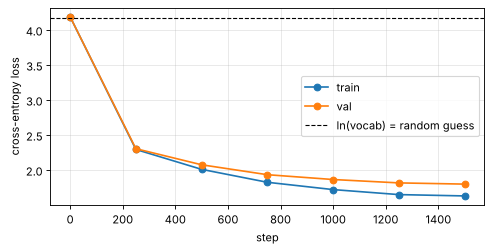

In [6]:
h = np.array(history)
plt.plot(h[:, 0], h[:, 1], "o-", label="train"); plt.plot(h[:, 0], h[:, 2], "o-", label="val")
plt.axhline(math.log(vocab_size), color="k", ls="--", lw=1, label="ln(vocab) = random guess")
plt.xlabel("step"); plt.ylabel("cross-entropy loss"); plt.legend(); plt.show()

- 시작 손실이 $\ln V$ 근처입니다. 초기화가 정상이라는 확인입니다. 여기서 크게 벗어나면 모델이나 손실 계산에 버그가 있습니다. (실제로 이 노트북을 만들 때 초기화 코드 `_init` 을 빼먹었더니 시작 손실이 80을 넘었습니다. PyTorch 임베딩의 기본 초기화는 표준편차 1이라 logits가 너무 커지기 때문입니다. `self.apply(self._init)` 줄을 지우고 직접 확인해 보세요.)
- train과 val 손실이 함께 내려갑니다. 두 곡선이 벌어지기 시작하면 과적합입니다.

## 5. 학습 과정에서 무엇이 생기나

저장해 둔 체크포인트에서 같은 시작 글자로 생성해 봅니다. **최종 가중치만 봐서는 알 수 없는 것**입니다.

In [7]:
start = torch.tensor([encode("\n")])
for step, state in snapshots.items():
    m = TinyGPT(vocab_size); m.load_state_dict(state); m.eval()
    print(f"--- step {step} ---\n{decode(m.generate(start, 120)[0])}\n")

--- step 0 ---

t3ZrjmhPPdkhRxLsXltUW?jHTu
?eghayU&aNdkIgAlsv,BUMycoRD$BygXO ntw
kVrM z&?j DJR!sOEHelC!BTg3eU&PRCslMa-'3KypwrWi&kMGRJIRc

--- step 100 ---

th remhis ke whselter ouca neaman y id I tlste greco atoy h fotherere he n thin berelouseane he tse atho y or it per anc



--- step 500 ---

Thare his kiss selle, of a mearen youd I tlet,
AMy courser thith here hath woul be has sould him;
That of porditked manc

--- step 1500 ---

Thou make king sell it of yoes,
And in I the farterous with that here hath think
And see and him stants, your was we all



글자의 빈도 → 단어처럼 보이는 덩어리와 줄바꿈 → 등장인물 이름과 대사 형식의 순서로 생겨납니다. Pythia의 154개 체크포인트가 연구에 쓰이는 방식이 이것의 대규모 버전입니다.

## 6. 가중치 저장과 재로딩

공개 모델 저장소의 핵심 파일 세 가지를 직접 만듭니다: `model.safetensors`(가중치), `config.json`(구조), 토크나이저 파일.

✍️ **예측**: 가중치 파일의 크기는? (파라미터 수 × 4바이트)

In [8]:
from safetensors.torch import save_model, load_model
out_dir = tempfile.mkdtemp()
model.eval()
save_model(model, os.path.join(out_dir, "model.safetensors"))
json.dump(model.config, open(os.path.join(out_dir, "config.json"), "w"))
json.dump({"type": "char", "vocab": chars}, open(os.path.join(out_dir, "tokenizer.json"), "w"))
for f in sorted(os.listdir(out_dir)): print(f"{f:20s} {os.path.getsize(os.path.join(out_dir, f)):>10,} bytes")

# "다른 사람"의 입장에서: 파일만 가지고 모델을 복원한다
cfg = json.load(open(os.path.join(out_dir, "config.json")))
restored = TinyGPT(**cfg); load_model(restored, os.path.join(out_dir, "model.safetensors")); restored.eval()
x = torch.tensor([encode("ROMEO:")])
print("복원한 모델의 출력이 원래와 같은가:", torch.allclose(model(x)[0], restored(x)[0]))

config.json                  90 bytes
model.safetensors     3,235,016 bytes
tokenizer.json              353 bytes


복원한 모델의 출력이 원래와 같은가: True


## 7. 모델 카드 쓰기

가중치만 올리면 아무도(미래의 나도) 이것이 무엇인지 모릅니다. 최소한 아래 항목을 적습니다.

In [9]:
final = estimate_loss(model)
card = f"""# tiny-gpt-shakespeare-char

- 구조: 디코더 전용 Transformer, {cfg['n_layer']}층 / 폭 {cfg['d']} / {cfg['n_head']}헤드 / 문맥 {cfg['block_size']}, 파라미터 {n_params:,}개
- 토크나이저: 글자 단위, 어휘 {vocab_size}
- 학습 데이터: tiny Shakespeare 앞 90% ({len(train_data):,} 토큰), 검증: 뒤 10%
- 학습: AdamW, 최대 학습률 {max_lr}, warmup {warmup}스텝 + 코사인, 배치 {batch_size}, {max_steps}스텝, 기울기 클리핑 1.0
- 결과: train 손실 {final['train']:.3f}, val 손실 {final['val']:.3f} (무작위 추측 {math.log(vocab_size):.3f})
- 한계: 글자 단위라 단어의 뜻을 모른다. 셰익스피어 말투만 흉내 낸다. 사실·지시 수행 능력 없음.
- 재현: 이 노트북을 위에서 아래로 실행 (시드 0)
"""
open(os.path.join(out_dir, "README.md"), "w").write(card); print(card)

# tiny-gpt-shakespeare-char

- 구조: 디코더 전용 Transformer, 4층 / 폭 128 / 4헤드 / 문맥 64, 파라미터 807,808개
- 토크나이저: 글자 단위, 어휘 65
- 학습 데이터: tiny Shakespeare 앞 90% (1,003,854 토큰), 검증: 뒤 10%
- 학습: AdamW, 최대 학습률 0.001, warmup 100스텝 + 코사인, 배치 32, 1500스텝, 기울기 클리핑 1.0
- 결과: train 손실 1.632, val 손실 1.801 (무작위 추측 4.174)
- 한계: 글자 단위라 단어의 뜻을 모른다. 셰익스피어 말투만 흉내 낸다. 사실·지시 수행 능력 없음.
- 재현: 이 노트북을 위에서 아래로 실행 (시드 0)



---
## 직접 해보기

1. **(위치 정보 제거)** `use_pos=False` 로 학습하면 val 손실이 어떻게 되나요? 먼저 예측하세요. ([LLM Lab 01](../../04_NLP_LLM/labs/lab01_tokenizer_attention_from_scratch.ipynb) 6절 참고)
2. **(파라미터 수)** 임베딩·블록·정규화를 손으로 더해 파라미터 수를 맞혀 보세요.
3. **(설정 바꾸기)** 한 번에 하나만 바꿔 다시 학습하고 "바꾼 것 → 예측 → val 손실 → 해석"을 기록하세요: 폭 64 / 층 2 / 학습률 1e-2 / warmup 없음.
4. **(다음 단계)** nanoGPT 저장소의 `model.py` 와 이 노트북의 `Block`, `TinyGPT` 를 한 줄씩 대응시켜 보세요.

In [10]:
# TODO 1: use_pos=False 로 학습

# TODO 2: 파라미터 수 손계산

---
## 정답 예시 (먼저 풀어 본 뒤 확인)

In [11]:
# 1. 위치 임베딩 없이 (비교를 위해 600스텝만)
torch.manual_seed(0); no_pos = TinyGPT(vocab_size, use_pos=False); h_np, _ = train(no_pos, steps=600, log_every=600)
torch.manual_seed(0); with_pos = TinyGPT(vocab_size); h_wp, _ = train(with_pos, steps=600, log_every=600)
print(f"600스텝 뒤 val 손실  위치 임베딩 있음: {h_wp[-1][2]:.3f}   없음: {h_np[-1][2]:.3f}")

step     0 | lr 1.00e-05 | train 4.199 | val 4.196


step   600 | lr 7.17e-04 | train 2.086 | val 2.150
학습 시간 31초


step     0 | lr 1.00e-05 | train 4.191 | val 4.190


step   600 | lr 7.17e-04 | train 1.928 | val 2.005
학습 시간 32초
600스텝 뒤 val 손실  위치 임베딩 있음: 2.005   없음: 2.150


In [12]:
# 2. 파라미터 수
d, Lyr, V, T = cfg["d"], cfg["n_layer"], vocab_size, cfg["block_size"]
block = 3 * d * d + d * d + (d * 4 * d + 4 * d) + (4 * d * d + d) + 2 * 2 * d     # qkv, proj, mlp 두 층(+bias), LayerNorm 두 개(가중치+bias)
by_hand = V * d + T * d + Lyr * block + 2 * d                                       # 토큰 임베딩(출력층과 공유) + 위치 임베딩 + 블록들 + 마지막 LayerNorm
print(f"손계산 {by_hand:,}  vs  실제 {n_params:,}  → 일치: {by_hand == n_params}")

손계산 807,808  vs  실제 807,808  → 일치: True


**해석**: 위치 임베딩이 없으면 모델은 "최근 64글자에 어떤 글자들이 있었는지"만 알고 순서를 모릅니다. causal mask 덕분에 약간의 순서 정보는 새어 들어가지만 손실이 뚜렷이 높습니다.

---
## 문서로 돌아가기

| 방금 한 것 | 확인할 곳 |
|---|---|
| 3절 구조 | nanoGPT `model.py`. 요즘 모델과의 차이(RMSNorm, RoPE, SwiGLU, GQA)는 [03_training-pipeline.md](../03_training-pipeline.md) 3절과 [Lab 01](lab01_inspect_open_model.ipynb) |
| 4절 학습 루프 | nanoGPT `train.py` 의 `get_lr`, nanochat `scripts/base_train.py` |
| 5절 체크포인트 | [04_model-guides.md](../04_model-guides.md)의 Pythia 절 |
| 6~7절 | [SmolLM3 모델 카드](https://huggingface.co/HuggingFaceTB/SmolLM3-3B) — 내가 쓴 카드에 없는 항목은? |

## 기억 점검

1. 학습 전 손실이 $\ln V$ 근처여야 하는 이유는?
2. 입력 `x` 와 정답 `y` 는 어떤 관계인가? 한 배치에서 예측은 몇 번 일어나나?
3. warmup과 기울기 클리핑은 각각 무엇을 막는가?
4. 모델을 다른 사람이 복원하려면 어떤 파일들이 필요한가?
5. train 손실만 보고하고 val 손실이 없는 모델 카드를 보면 무엇을 의심해야 하나?

<details><summary>답 확인</summary>

1. 초기 모델은 모든 토큰에 거의 같은 확률을 주므로 교차 엔트로피가 균등 분포의 값 $\ln V$ 가 된다.
2. `y` 는 `x` 를 한 칸 민 것. 모든 위치에서 다음 토큰을 예측하므로 배치 크기 × 문맥 길이 번.
3. warmup: 학습 초반의 불안정(큰 갱신으로 인한 발산). 클리핑: 드물게 생기는 매우 큰 기울기로 인한 폭주.
4. 가중치, 구조 설정(config), 토크나이저(어휘·규칙). 모델 클래스 코드도 필요하다.
5. 과적합 여부를 알 수 없다. 학습 데이터를 외웠을 수 있다.
</details>